In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
import os
print(os.getcwd())

/Users/apple


In [5]:
df=pd.read_csv(os.path.expanduser("~/Downloads/StudentPerformanceFactors.csv"))
print(df.head())

   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality  \
0             Ye

In [6]:
numeric_df=df.select_dtypes(include=["number"])
print(numeric_df.columns)
print(numeric_df.head())

Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='str')
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Exam_Score  
0                  3          67  
1                  4          61  
2                  4          74  
3                  4          71  
4                  4          70  


In [7]:
numeric_df=numeric_df.dropna()
print(numeric_df.isnull().sum())

Hours_Studied        0
Attendance           0
Sleep_Hours          0
Previous_Scores      0
Tutoring_Sessions    0
Physical_Activity    0
Exam_Score           0
dtype: int64


In [11]:
normalizer=MinMaxScaler()
normalized_data=normalizer.fit_transform(numeric_df)
normalized_df=pd.DataFrame(normalized_data,columns=numeric_df.columns)
print(normalized_df.head().round(2))

   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.51        0.60         0.50             0.46               0.00   
1           0.42        0.10         0.67             0.18               0.25   
2           0.53        0.95         0.50             0.82               0.25   
3           0.65        0.73         0.67             0.96               0.12   
4           0.42        0.80         0.33             0.30               0.38   

   Physical_Activity  Exam_Score  
0               0.50        0.26  
1               0.67        0.13  
2               0.67        0.41  
3               0.67        0.35  
4               0.67        0.33  


In [12]:
print(normalized_df.head().round(4))

   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0         0.5116       0.600       0.5000             0.46              0.000   
1         0.4186       0.100       0.6667             0.18              0.250   
2         0.5349       0.950       0.5000             0.82              0.250   
3         0.6512       0.725       0.6667             0.96              0.125   
4         0.4186       0.800       0.3333             0.30              0.375   

   Physical_Activity  Exam_Score  
0             0.5000      0.2609  
1             0.6667      0.1304  
2             0.6667      0.4130  
3             0.6667      0.3478  
4             0.6667      0.3261  


In [14]:
scaler=StandardScaler()
standardized_data=scaler.fit_transform(numeric_df)
standardized_df=pd.DataFrame(standardized_data,columns=numeric_df.columns)
print(standardized_df.head().round(2))


   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.50        0.35        -0.02            -0.14              -1.21   
1          -0.16       -1.38         0.66            -1.12               0.41   
2           0.67        1.56        -0.02             1.11               0.41   
3           1.51        0.78         0.66             1.59              -0.40   
4          -0.16        1.04        -0.70            -0.70               1.22   

   Physical_Activity  Exam_Score  
0               0.03       -0.06  
1               1.00       -1.60  
2               1.00        1.74  
3               1.00        0.97  
4               1.00        0.71  


In [19]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(standardized_df)
pca_df=pd.DataFrame(pca_data,columns=["PC1","PC3"])
print(pca_df.head().round(2))
print("Variance ratio:",pca.explained_variance_ratio_)
print("Total variance retained:",round(pca.explained_variance_ratio_.sum()*100,2),"%")

    PC1   PC3
0  0.15  0.59
1 -2.06 -0.19
2  2.59  0.04
3  1.91  1.56
4  1.09 -1.61
Variance ratio: [0.25214912 0.1499744 ]
Total variance retained: 40.21 %


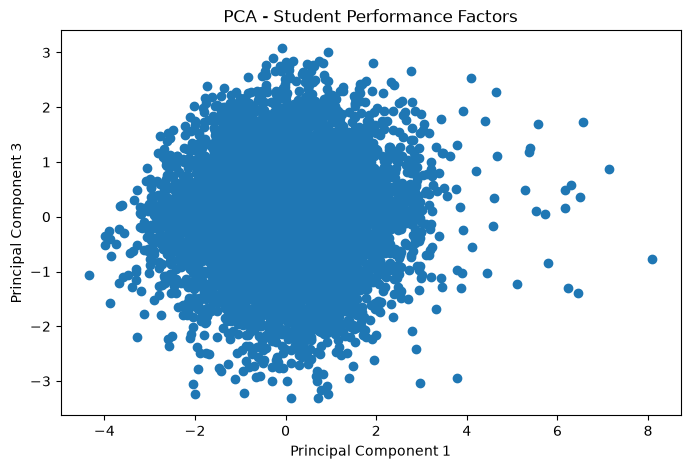

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(pca_df["PC1"], pca_df["PC3"])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 3")
plt.title("PCA - Student Performance Factors")

plt.show()